1. Salario
2. Anos_Educ_Superior
3. Tempo_de_Carreira

In [ ]:
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

import statsmodels.api as sm

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/!dados/Analíse-Preditiva/base_funcionarios_v3.csv', index_col=0)
df.head()
df = df.drop(columns='Tempo_Empresa')

In [ ]:
df.isna().sum

<bound method DataFrame.sum of     Salario  Anos_Educ_Superior  Tempo_de_Carreira
0     False               False              False
1     False               False              False
2     False               False              False
3     False               False              False
4     False               False              False
5     False               False              False
6     False               False              False
7     False               False              False
8     False               False              False
9     False               False              False
10    False               False              False
11    False               False              False
12    False               False              False
13    False               False              False
14    False               False              False
15    False               False              False
16    False               False              False
17    False               False              False
18    False               False              False
19    False               False              False
20    False               False              False
21    False               False              False
22    False               False              False
23    False               False              False
24    False               False              False
25    False               False              False
26    False               False              False
27    False               False              False
28    False               False              False
29    False               False              False
30    False               False              False
31    False               False              False
32    False               False              False
33    False               False              False
34    False               False              False
35    False               False              False
36    False               False              False
37    False               False              False
38    False               False              False
39    False               False              False
40    False               False              False
41    False               False              False
42    False               False              False
43    False               False              False
44    False               False              False
45    False               False              False>

In [ ]:
df.describe().round(2)

,Salario,Anos_Educ_Superior,Tempo_de_Carreira
count,46.00,46.00,46.00
mean,6969.80,5.07,21.19
std,1924.87,2.84,15.87
min,4139.50,0.00,-3.24
25%,5818.35,4.00,9.62
50%,6394.75,5.00,17.69
75%,7972.40,6.00,29.77
max,12118.10,12.00,67.86


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 46 entries, 0 to 45
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Salario             46 non-null     float64
 1   Anos_Educ_Superior  46 non-null     int64  
 2   Tempo_de_Carreira   46 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 1.4 KB


In [ ]:
df['Tempo_de_Carreira'] = df['Tempo_de_Carreira'].abs()

In [ ]:
df.corr()

,Salario,Anos_Educ_Superior,Tempo_de_Carreira
Salario,1.000000,0.776992,0.708182
Anos_Educ_Superior,0.776992,1.000000,0.612984
Tempo_de_Carreira,0.708182,0.612984,1.000000


<Axes: xlabel='Anos_Educ_Superior', ylabel='Salario'>

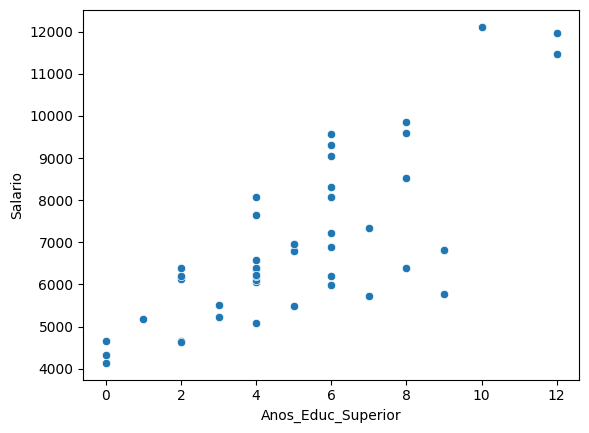

In [ ]:
sns.scatterplot(df, x='Anos_Educ_Superior', y='Salario')

<Axes: xlabel='Tempo_de_Carreira', ylabel='Salario'>

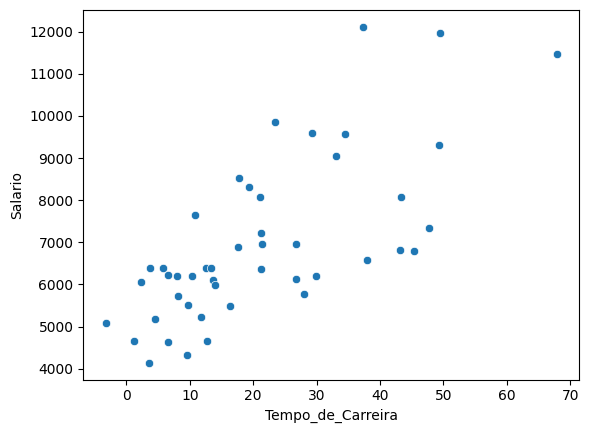

In [ ]:
sns.scatterplot(df, x='Tempo_de_Carreira', y='Salario')

<Axes: >

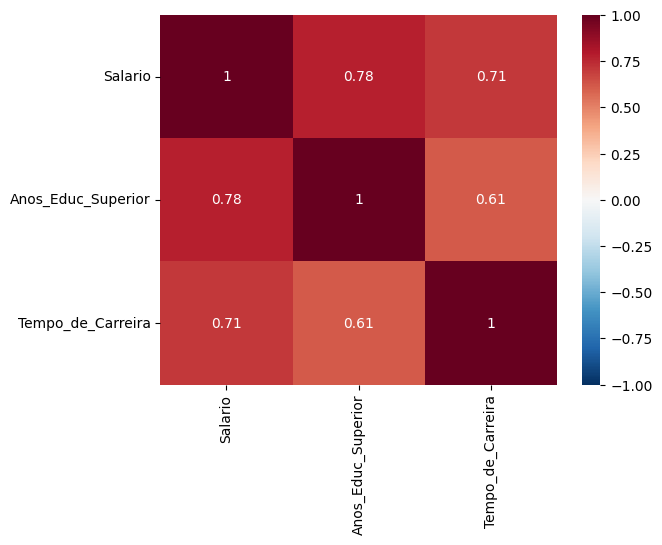

In [ ]:
sns.heatmap(
    df.corr(),
    vmin=-1,vmax=1,
    cmap = 'RdBu_r',
    annot=True
)

In [ ]:
y = df['Salario']
df['interceptor'] = 1
x= df[['Anos_Educ_Superior', 'interceptor', 'Tempo_de_Carreira']]

In [ ]:
modelo = sm.OLS(y,x)

In [ ]:
resultado = modelo.fit()

In [ ]:
print(resultado.summary())
#Porcentagem 69%
#Anos_Edu_Superior = 372.36 - 526.73
#intercepto = 4128.71 - 4301.80
#Tempo_de_Carreira = 45.1

                            OLS Regression Results                            
Dep. Variable:                Salario   R-squared:                       0.690
Model:                            OLS   Adj. R-squared:                  0.675
Method:                 Least Squares   F-statistic:                     47.82
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           1.17e-11
Time:                        18:13:08   Log-Likelihood:                -385.72
No. Observations:                  46   AIC:                             777.4
Df Residuals:                      43   BIC:                             782.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Anos_Educ_Superior   372.3603     72

In [ ]:
df['Novo_Salario'] = df['Anos_Edu_Superior'] * 526.73 + 4301.80 + df['Tempo_de_Carreira'] * 45.1
display(df[['Salario', 'Novo_Salario']])